In [1]:
import os, sys
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath('..'))

from src.storage.db_client import get_db_connection, get_candles_for_training

conn = get_db_connection()
df = get_candles_for_training(conn, "BTCUSDT", days = 30)
df["price_change_pct"] = df["avg_price"].pct_change() * 100
df.describe()

,minute_start,avg_price,min_price,max_price,volume,price_change_pct
count,43196,43196.000000,43196.000000,43196.000000,43196.000000,4.319500e+04
mean,2026-10-19 09:35:30.000000256,81666.261850,81649.247810,81683.578895,9.702481,-2.304866e-04
min,2026-10-04 09:38:00,76394.287818,76325.980000,76436.230000,0.025630,-7.516904e-01
25%,2026-10-11 21:36:45,80534.593332,80518.892500,80547.572500,2.941205,-1.682984e-02
50%,2026-10-19 09:35:30,81763.001967,81746.640000,81780.005000,5.813985,-6.087300e-07
75%,2026-10-26 21:34:15,83050.005662,83044.000000,83057.975000,10.928010,1.611113e-02
max,2026-11-03 09:33:00,86989.622778,86944.670000,86999.110000,737.617320,4.206238e-01
std,NaN,2271.955151,2272.597738,2271.287407,16.625809,3.885788e-02


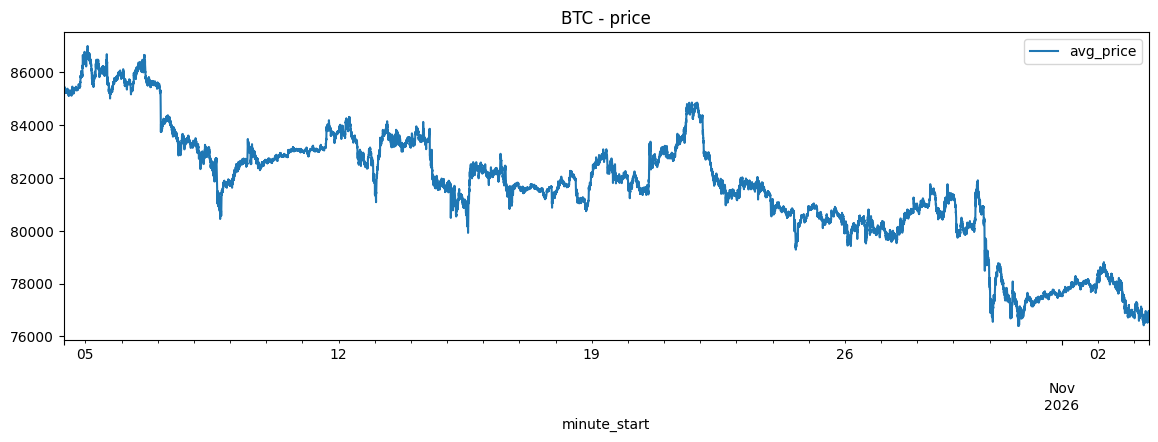

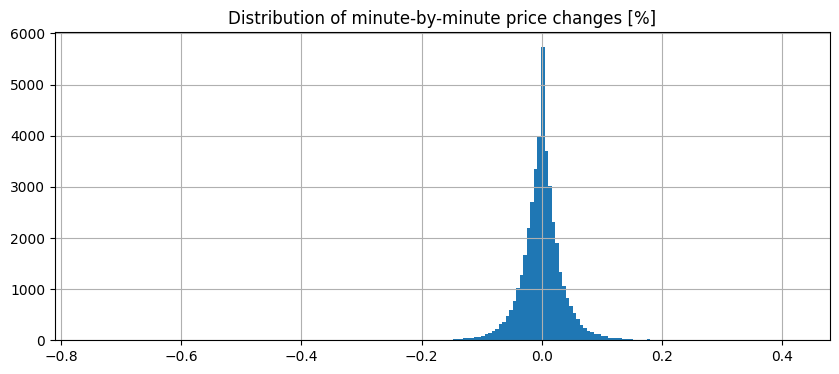

Highest price changes:


,minute_start,avg_price,min_price,max_price,volume,price_change_pct
14572,2026-10-14 12:30:00,83225.704001,82730.88,83933.00,737.61732,-0.751690
15410,2026-10-15 02:28:00,80484.053698,80226.35,80853.45,510.97049,-0.569558
3863,2026-10-07 02:01:00,83922.067554,83615.00,84327.88,512.81174,-0.544179
16112,2026-10-15 14:10:00,81238.189255,80992.00,81424.00,150.63654,0.415541
36670,2026-10-29 20:48:00,78813.975763,78501.52,78963.40,125.69388,0.420624
0,2026-10-04 09:38:00,85220.365205,85210.00,85232.37,4.56855,NaN


In [2]:
df.plot(x = "minute_start", y = "avg_price", figsize = (14, 4), title = "BTC - price")
plt.show()

df["price_change_pct"].hist(bins = 200, figsize = (10, 4))
plt.title("Distribution of minute-by-minute price changes [%]")
plt.show()

print("Highest price changes:")
df.sort_values("price_change_pct").iloc[[0, 1, 2, -3, -2, -1]]